# Machine Downtime Analysis — Part 2: Charts and Findings

In Part 1 you found three things in the downtime log. Now we'll turn them into **charts** and a **short summary for the plant manager**.

This is the part that matters most in a real job. A manager won't read your SQL. They'll look at a chart for five seconds and read three sentences. Your job is to make those count.

**Before you start:** keep `downtime_log.csv` in the same folder as this notebook. This notebook reloads the data itself, so it doesn't depend on Part 1 being open.

**If you get "No module named matplotlib":** run `%pip install matplotlib` in a cell, then restart the kernel (Kernel → Restart).

## Step 1: Load the tools and the data
Same setup as Part 1, plus **matplotlib**, Python's main charting library.

In [2]:
%pip install matplotlib

   ---------------------------------------- 0.0/9.3 MB ? eta -:--:--
   ---------------------------------------- 9.3/9.3 MB 59.9 MB/s eta 0:00:00
   ---------------------------------------- 0.0/2.5 MB ? eta -:--:--
   ---------------------------------------- 2.5/2.5 MB 46.9 MB/s eta 0:00:00
   ---------------------------------------- 0.0/7.2 MB ? eta -:--:--
   ---------------------------------------- 7.2/7.2 MB 75.7 MB/s eta 0:00:00
Note: you may need to restart the kernel to use updated packages.


  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.

[notice] A new release of pip is available: 25.0.1 -> 26.2.1
[notice] To update, run: C:\Users\Acer\AppData\Local\Programs\Python\Python313\python.exe -m pip install --upgrade pip


In [3]:
import pandas as pd               # tables
import sqlite3                    # the SQL database
import matplotlib.pyplot as plt   # charts. "pyplot" is the part of matplotlib
                                  # that draws charts; "plt" is its usual nickname

# Load the CSV into a SQL database, exactly like Part 1
df = pd.read_csv("downtime_log.csv")
conn = sqlite3.connect(":memory:")
df.to_sql("downtime", conn, index=False, if_exists="replace")

def sql(query):
    """Run a SQL query on our database and return the result as a table."""
    return pd.read_sql_query(query, conn)

print("Loaded", len(df), "events.")

Loaded 621 events.


## Step 2: Chart 1 — Where is the time going?

**The point of this chart:** show which causes cost the most time, and separate *planned* downtime (preventive maintenance, tool changes — the plant chooses these) from *unplanned* downtime (breakdowns — the real problem).

We'll do it in two parts: first **SQL gets the numbers**, then **matplotlib draws them**. That's how analysts usually work.

**New SQL:** `ROUND(SUM(duration_min) / 60.0, 1)` converts minutes to **hours**, since "85 hours" means more to a manager than "5,125 minutes." Again `60.0`, not `60`, so we keep the decimals.

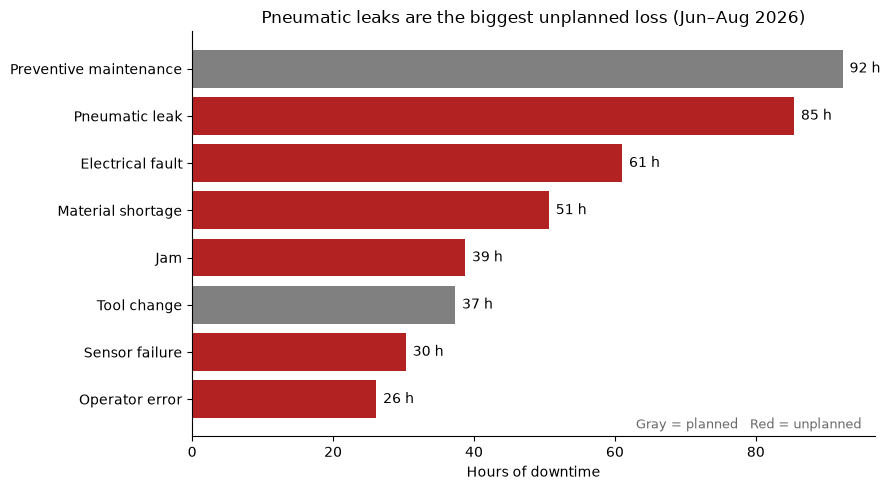

In [4]:
# --- Get the numbers with SQL ---
by_cause = sql("""
    SELECT cause,
           ROUND(SUM(duration_min) / 60.0, 1) AS hours_lost   -- minutes -> hours
    FROM downtime
    GROUP BY cause
    ORDER BY hours_lost ASC   -- smallest first, so the biggest bar ends up
                              -- at the TOP of a horizontal bar chart
""")

# --- Decide each bar's color ---
# These two causes are planned (scheduled on purpose). Everything else is a breakdown.
planned = ["Preventive maintenance", "Tool change"]

# This is a "list comprehension" (you saw these on Codecademy).
# For each cause: gray if it's planned, red if it's unplanned.
colors = ["gray" if c in planned else "firebrick" for c in by_cause["cause"]]

# --- Draw the chart ---
# figsize=(9, 5) sets the size: 9 wide, 5 tall (in inches)
fig, ax = plt.subplots(figsize=(9, 5))
#   fig = the whole picture (the canvas)
#   ax  = the chart drawn on it. We call methods on ax to build the chart.

# barh = horizontal bar chart. Horizontal makes long labels easy to read.
#   first argument  -> the label for each bar (the causes)
#   second argument -> how long each bar is (the hours)
ax.barh(by_cause["cause"], by_cause["hours_lost"], color=colors)

# Titles and labels. Write titles that state the FINDING, not just the topic.
ax.set_title("Pneumatic leaks are the biggest unplanned loss (Jun–Aug 2026)")
ax.set_xlabel("Hours of downtime")

# Write the exact number at the end of each bar so nobody has to guess.
# enumerate() hands back each bar's position (i = 0, 1, 2...) along with its hours.
for i, hours in enumerate(by_cause["hours_lost"]):
    ax.text(hours + 1, i, f"{hours:.0f} h", va="center")
    #       ^ x position: just past the end of the bar
    #                ^ y position: the same row as the bar
    #                   ^ the text, e.g. "85 h" (.0f = no decimals)
    #                                      ^ va="center": vertically centered

# A small note explaining the colors
ax.text(0.98, 0.02, "Gray = planned   Red = unplanned",
        transform=ax.transAxes,   # position as a fraction of the chart (0 to 1)
        ha="right", fontsize=9, color="dimgray")

# Remove the top and right border lines. A cleaner look, common in reports.
ax.spines[["top", "right"]].set_visible(False)

plt.tight_layout()   # stops labels from getting cut off at the edges

# Save the chart as an image file (in the same folder as this notebook).
# You'll use these images in your GitHub README later.
# dpi=150 means a sharp, good-quality image.
plt.savefig("chart1_hours_by_cause.png", dpi=150)

plt.show()           # display the chart in the notebook

## Step 3: Chart 2 — Why does Press 2 keep going down?

**The point of this chart:** Press 2 loses the most time of any machine, and this shows why.

This is the same SQL you wrote in Part 1, Step 7, now drawn as a chart. We highlight the one bar that matters in a strong color and make the rest gray. That steers the reader's eye straight to the finding.

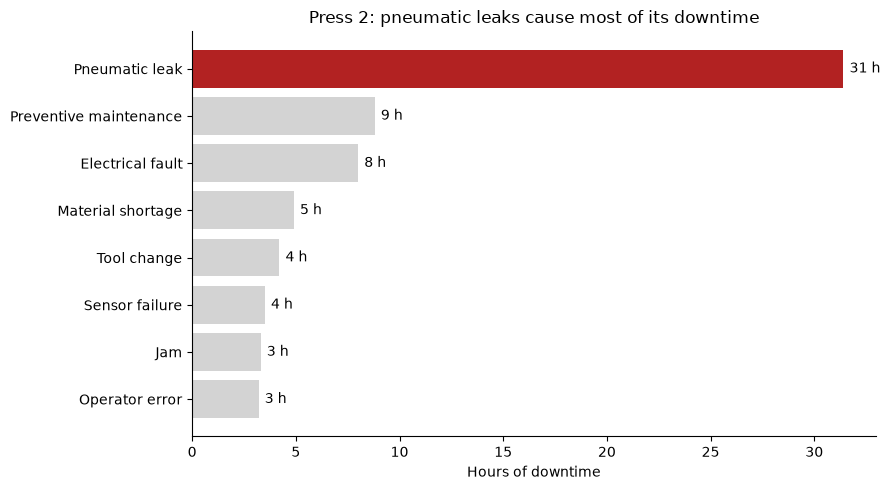

In [5]:
# --- Get the numbers ---
press2 = sql("""
    SELECT cause,
           ROUND(SUM(duration_min) / 60.0, 1) AS hours_lost
    FROM downtime
    WHERE machine = 'Press 2'
    GROUP BY cause
    ORDER BY hours_lost ASC
""")

# Highlight only pneumatic leaks; everything else gray
colors = ["firebrick" if c == "Pneumatic leak" else "lightgray" for c in press2["cause"]]

# --- Draw the chart (same steps as Chart 1) ---
fig, ax = plt.subplots(figsize=(9, 5))
ax.barh(press2["cause"], press2["hours_lost"], color=colors)
ax.set_title("Press 2: pneumatic leaks cause most of its downtime")
ax.set_xlabel("Hours of downtime")

for i, hours in enumerate(press2["hours_lost"]):
    ax.text(hours + 0.3, i, f"{hours:.0f} h", va="center")

ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.savefig("chart2_press2_causes.png", dpi=150)
plt.show()

## Step 4: Chart 3 — The 3rd shift operator-error rate

**The point of this chart:** compare shifts *fairly*, using the percentage you calculated in Part 1, not raw counts.

**New:** `ORDER BY CASE ...` puts the shifts in their natural order (1st, 2nd, 3rd) instead of sorting by the number. For time-based things like shifts, natural order is easier to read.

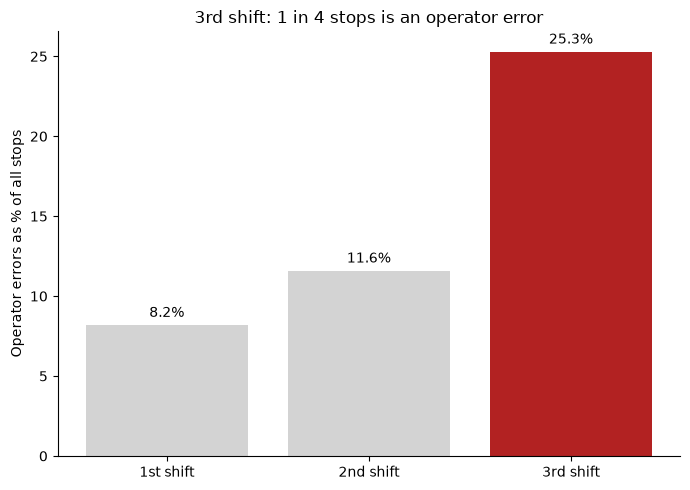

In [6]:
# --- Get the numbers (your percentage query from Part 1) ---
shifts = sql("""
    SELECT shift,
           ROUND(100.0 * SUM(CASE WHEN cause = 'Operator error' THEN 1 ELSE 0 END)
                 / COUNT(*), 1) AS pct_operator_error
    FROM downtime
    GROUP BY shift
    ORDER BY CASE shift WHEN '1st' THEN 1   -- put 1st shift first,
                        WHEN '2nd' THEN 2   -- then 2nd,
                        ELSE 3 END          -- then 3rd
""")

colors = ["firebrick" if s == "3rd" else "lightgray" for s in shifts["shift"]]

# --- Draw it ---
# This time a regular VERTICAL bar chart (bar instead of barh),
# because there are only 3 short labels.
fig, ax = plt.subplots(figsize=(7, 5))
ax.bar(shifts["shift"] + " shift", shifts["pct_operator_error"], color=colors)
#      ^ adds the word " shift" to each label: "1st" becomes "1st shift"

ax.set_title("3rd shift: 1 in 4 stops is an operator error")
ax.set_ylabel("Operator errors as % of all stops")

# Put the percentage on top of each bar
for i, pct in enumerate(shifts["pct_operator_error"]):
    ax.text(i, pct + 0.5, f"{pct}%", ha="center")
    #       ^ x: the bar's position   ^ y: just above the bar

ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.savefig("chart3_shift_errors.png", dpi=150)
plt.show()

## Step 5: 🔧 Your turn — the summary for the plant manager

This is the most important cell in the project, and **it needs to be in your words.** Hiring managers read this part to see whether you can think like an analyst, not just run code.

**How to edit this cell:** double-click it to edit, then press Shift + Enter to display it again.

Use this structure. The first finding is written as an example; write the other two the same way. Each finding answers: **what happened, how big it is, and what to do about it.**

---

### Summary: Machine downtime, June–August 2026

**Bottom line:** Reducing pneumatic leaks with special attention to Press 2, and looking into 3rd shift errors would recover the most downtime for the plant.

**1. Pneumatic leaks are the largest source of unplanned downtime.** They cost about 85 hours over three months, more than any other breakdown cause, and Press 2 accounts for over a third of that. **Recommendation:** inspect Press 2's air lines, fittings, and seals, and add a leak check to its preventive maintenance routine.

**2. 3rd shift has an operator-error problem.** 3rd shift's operator error rate is more than 2 times that of 2nd shift and 3 times that of 1st shift. 3rd shift is the night shift and it may be that the operators are tired because of the time of day. Other possibilities include shift lead supervision issues, inadequate training, experience,  or number of workers. **Recommendation:** Walk the floor with 3rd shift leads to observe and report findings.

**3. Jams happen most often but cost the least time per event.** Jams are the most frequent interruptions but account for an average downtime per event. 151 total events vs 15 minutes average duration, but a total of nearly 39 hours. The Packager accounts for 46 events, about double the rate of any other machine. **Recommendation:** Observe machine jams for possible solutions. Operator interviews regarding the jams may lead to more insight.

**Note on the data:** This data does not take into consideration the production volume per shift.